In [1]:
!pip install flwr[simulation] scikit-learn matplotlib


In [2]:
import torch
import flwr as fl
from sklearn.metrics import cohen_kappa_score, f1_score
import matplotlib.pyplot as plt

print(f"PyTorch Version: {torch.__version__}")
print(f"Flower Version:  {fl.__version__}")

# Check GPU
if torch.cuda.is_available():
    device = torch.device("cuda")
    print(f" SUCCESS: Using GPU -> {torch.cuda.get_device_name(0)}")
else:
    device = torch.device("cpu")
    print(" WARNING: GPU not detected, running on CPU.")

PyTorch Version: 2.14.1+cu130
Flower Version:  1.43.0
 SUCCESS: Using GPU -> NVIDIA L4


In [3]:
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split

# 1. Image preparation: Convert pictures to PyTorch tensors and normalize pixel colors
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])

# 2. Download CIFAR-10
print("Downloading CIFAR-10 dataset...")
train_dataset = torchvision.datasets.CIFAR10(root="./data", train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.CIFAR10(root="./data", train=False, download=True, transform=transform)

# 3. Create IID Partitions for 5 clients (50,000 images / 5 = 10,000 images each)
NUM_CLIENTS = 5
split_sizes = [len(train_dataset) // NUM_CLIENTS] * NUM_CLIENTS
client_datasets = random_split(train_dataset, split_sizes, generator=torch.Generator().manual_seed(42))

# 4. Central Test DataLoader (used by the Server to test global model)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

print(f"Total training images: {len(train_dataset)}")
print(f"Divided into {NUM_CLIENTS} clients: {[len(ds) for ds in client_datasets]} images each.")
print(f"Central test set size: {len(test_dataset)} images.")

100%|██████████| 170M/170M [00:28<00:00, 5.97MB/s]


Total training images: 50000
Divided into 5 clients: [10000, 10000, 10000, 10000, 10000] images each.
Central test set size: 10000 images.


In [4]:
import torch.nn as nn
import torch.nn.functional as F

# 1. Define the Neural Network Architecture
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        # Layer 1: Takes 3 color channels (RGB) -> outputs 32 feature maps
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        # Layer 2: 32 feature maps -> 64 feature maps
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)

        # Fully connected layers to classify into 10 categories
        self.fc1 = nn.Linear(64 * 8 * 8, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x))) # Size: 32x16x16
        x = self.pool(F.relu(self.conv2(x))) # Size: 64x8x8
        x = x.view(-1, 64 * 8 * 8)          # Flatten
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

# 2. Local Training Function (Run by each client)
def train_one_epoch(net, dataloader, optimizer, criterion, device):
    net.train()
    for images, labels in dataloader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = net(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

# 3. Evaluation Function (Calculates Loss, Accuracy, F1, Cohen's Kappa)
def evaluate_model(net, dataloader, device):
    net.eval()
    criterion = nn.CrossEntropyLoss()
    total_loss = 0.0
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)
            outputs = net(images)
            loss = criterion(outputs, labels)
            total_loss += loss.item() * images.size(0)

            preds = torch.argmax(outputs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(dataloader.dataset)
    acc = sum([p == t for p, t in zip(all_preds, all_targets)]) / len(all_targets)

    # Calculate required metrics
    f1 = f1_score(all_targets, all_preds, average='weighted')
    kappa = cohen_kappa_score(all_targets, all_preds)

    return avg_loss, acc, f1, kappa

print(" SimpleCNN model & evaluation functions successfully defined!")

 SimpleCNN model & evaluation functions successfully defined!


In [5]:
import numpy as np

# 1. Helper: PyTorch weights -> NumPy arrays
def get_parameters(net):
    return [val.cpu().numpy() for _, val in net.state_dict().items()]

# 2. Helper: NumPy arrays -> PyTorch weights
def set_parameters(net, parameters):
    params_dict = zip(net.state_dict().keys(), parameters)
    state_dict = {k: torch.tensor(v) for k, v in params_dict}
    net.load_state_dict(state_dict, strict=True)

# 3. Define the standard honest Flower Client
class FlowerClient(fl.client.NumPyClient):
    def __init__(self, cid, train_subset):
        self.cid = cid
        self.train_loader = DataLoader(train_subset, batch_size=32, shuffle=True)
        self.net = SimpleCNN().to(device)

    def get_parameters(self, config):
        return get_parameters(self.net)

    def fit(self, parameters, config):
        # A. Update local model with current global parameters
        set_parameters(self.net, parameters)

        # B. Train for 1 local epoch on client's local images
        optimizer = torch.optim.SGD(self.net.parameters(), lr=0.01, momentum=0.9)
        criterion = nn.CrossEntropyLoss()
        train_one_epoch(self.net, self.train_loader, optimizer, criterion, device)

        # C. Return updated parameters back to central server
        return get_parameters(self.net), len(self.train_loader.dataset), {}

    def evaluate(self, parameters, config):
        set_parameters(self.net, parameters)
        loss, acc, f1, kappa = evaluate_model(self.net, self.train_loader, device)
        return float(loss), len(self.train_loader.dataset), {"accuracy": float(acc)}

# 4. Client generation function
def client_fn(context: fl.common.Context) -> fl.client.Client:
    cid = int(context.node_config["partition-id"])
    return FlowerClient(cid, client_datasets[cid]).to_client()

print("Flower Client and Parameter Helpers ready!")

Flower Client and Parameter Helpers ready!


In [6]:
# Lists to record the baseline metrics across all 35 rounds
baseline_history = {
    "rounds": [],
    "loss": [],
    "accuracy": [],
    "f1": [],
    "kappa": []
}

# The Central Server evaluation function: called after FedAvg combines weights in each round
def get_evaluate_fn():
    net = SimpleCNN().to(device)

    def evaluate(server_round: int, parameters: fl.common.NDArrays, config: dict):
        # Update server test model with the newly averaged global weights
        set_parameters(net, parameters)
        loss, acc, f1, kappa = evaluate_model(net, test_loader, device)

        # Save metrics for plotting and comparison
        baseline_history["rounds"].append(server_round)
        baseline_history["loss"].append(loss)
        baseline_history["accuracy"].append(acc)
        baseline_history["f1"].append(f1)
        baseline_history["kappa"].append(kappa)

        print(f" Round {server_round:02d} | Test Loss: {loss:.4f} | Acc: {acc*100:.2f}% | F1-Score: {f1:.4f} | Kappa: {kappa:.4f}")
        return loss, {"accuracy": acc, "f1": f1, "kappa": kappa}

    return evaluate

# 1. Setup FedAvg Strategy
strategy = fl.server.strategy.FedAvg(
    fraction_fit=1.0,           # Sample all 5 clients every round
    fraction_evaluate=0.0,      # Evaluate centrally on the test set
    min_fit_clients=5,
    min_available_clients=5,
    evaluate_fn=get_evaluate_fn(),
)

# 2. Run the 35-round Simulation!
print(" Starting 35-round Baseline Simulation (0 Attackers)...")
fl.simulation.start_simulation(
    client_fn=client_fn,
    num_clients=5,
    config=fl.server.ServerConfig(num_rounds=35),
    strategy=strategy,
    client_resources={"num_cpus": 2, "num_gpus": 0.2 if torch.cuda.is_available() else 0.0}
)

print("\n Baseline Simulation Complete!")

 Starting 35-round Baseline Simulation (0 Attackers)...


	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

          

 Round 00 | Test Loss: 2.3054 | Acc: 10.06% | F1-Score: 0.0330 | Kappa: 0.0007


INFO :      aggregate_fit: received 5 results and 0 failures
INFO :      fit progress: (1, 1.4076497024536132, {'accuracy': np.float64(0.5148), 'f1': 0.510535078501821, 'kappa': np.float64(0.4608888888888889)}, 10.019157625999924)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [ROUND 2]
INFO :      configure_fit: strategy sampled 5 clients (out of 5)


 Round 01 | Test Loss: 1.4076 | Acc: 51.48% | F1-Score: 0.5105 | Kappa: 0.4609


INFO :      aggregate_fit: received 5 results and 0 failures
INFO :      fit progress: (2, 1.1769662708282471, {'accuracy': np.float64(0.5923), 'f1': 0.5854015454902797, 'kappa': np.float64(0.5469999999999999)}, 15.667473030999645)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [ROUND 3]
INFO :      configure_fit: strategy sampled 5 clients (out of 5)


... (64 outputs left out)

 Round 34 | Test Loss: 1.8742 | Acc: 73.68% | F1-Score: 0.7370 | Kappa: 0.7076


INFO :      aggregate_fit: received 5 results and 0 failures
INFO :      fit progress: (35, 1.922310823059082, {'accuracy': np.float64(0.7359), 'f1': 0.7360198530797959, 'kappa': np.float64(0.7065555555555556)}, 196.84268208499998)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [SUMMARY]
INFO :      Run finished 35 round(s) in 196.84s
INFO :      	History (loss, centralized):
INFO :      		round 0: 2.305377415084839
INFO :      		round 1: 1.4076497024536132
INFO :      		round 2: 1.1769662708282471
INFO :      		round 3: 1.0515437675476074
INFO :      		round 4: 0.9762129302978516
INFO :      		round 5: 0.909397710323333

 Round 35 | Test Loss: 1.9223 | Acc: 73.59% | F1-Score: 0.7360 | Kappa: 0.7066

 Baseline Simulation Complete!


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


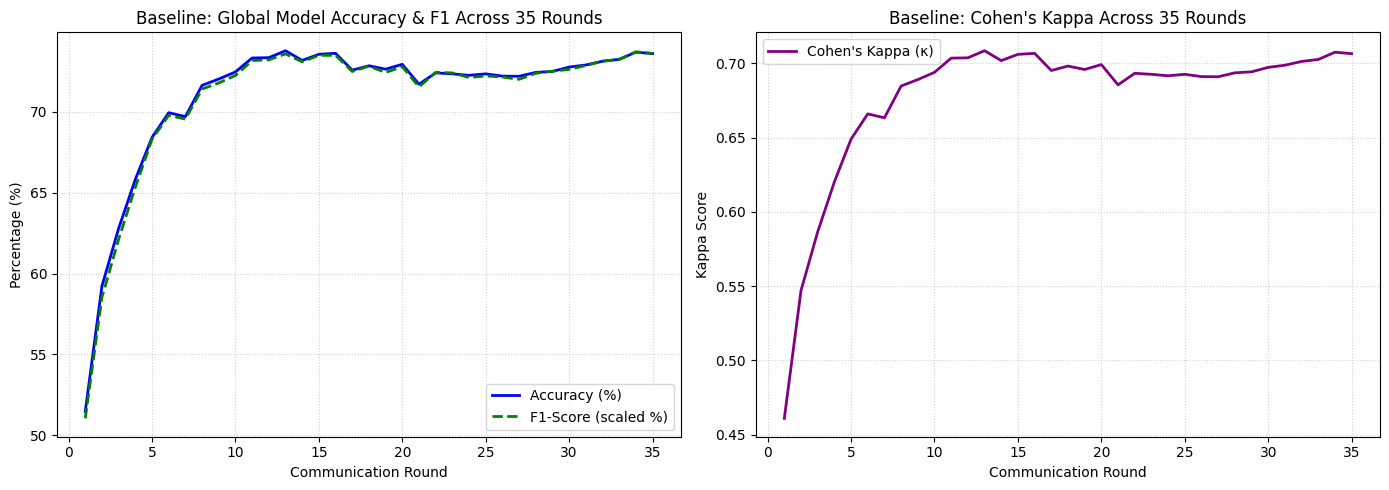

 Final Baseline Stats (Round 35):
 Accuracy: 73.59%
 F1-Score: 0.7360
 Kappa:    0.7066


In [7]:
import matplotlib.pyplot as plt

# Extract rounds (skip round 0 which was pre-training)
rounds = baseline_history["rounds"][1:]
acc = [a * 100 for a in baseline_history["accuracy"][1:]]
f1 = baseline_history["f1"][1:]
kappa = baseline_history["kappa"][1:]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot Accuracy & F1
ax1.plot(rounds, acc, label="Accuracy (%)", color="blue", linewidth=2)
ax1.plot(rounds, [f * 100 for f in f1], label="F1-Score (scaled %)", color="green", linestyle="--", linewidth=2)
ax1.set_title("Baseline: Global Model Accuracy & F1 Across 35 Rounds")
ax1.set_xlabel("Communication Round")
ax1.set_ylabel("Percentage (%)")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend()

# Plot Cohen's Kappa
ax2.plot(rounds, kappa, label="Cohen's Kappa (κ)", color="purple", linewidth=2)
ax2.set_title("Baseline: Cohen's Kappa Across 35 Rounds")
ax2.set_xlabel("Communication Round")
ax2.set_ylabel("Kappa Score")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

print(f" Final Baseline Stats (Round 35):")
print(f" Accuracy: {acc[-1]:.2f}%")
print(f" F1-Score: {f1[-1]:.4f}")
print(f" Kappa:    {kappa[-1]:.4f}")

In [8]:
from torch.utils.data import Dataset

# A helper dataset that flips labels: target = 9 - target
class PoisonedDataset(Dataset):
    def __init__(self, original_dataset):
        self.dataset = original_dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        image, label = self.dataset[idx]
        # Flip the label: 0->9, 1->8, 2->7, etc.
        poisoned_label = 9 - label
        return image, poisoned_label

# Define the Malicious Client that trains on poisoned (flipped) labels
class MaliciousFlowerClient(FlowerClient):
    def __init__(self, cid, train_subset):
        # Wrap the client's slice with the PoisonedDataset
        poisoned_subset = PoisonedDataset(train_subset)
        super().__init__(cid, poisoned_subset)
        # We can print a red tag so we know it's an attacker
        self.is_malicious = True

print(" MaliciousFlowerClient (Label-Flipping Attack) defined successfully!")

 MaliciousFlowerClient (Label-Flipping Attack) defined successfully!


In [9]:
# Storage for metrics with 1 attacked client
attack_1_history = {
    "rounds": [],
    "loss": [],
    "accuracy": [],
    "f1": [],
    "kappa": []
}

def get_evaluate_fn_attack_1():
    net = SimpleCNN().to(device)

    def evaluate(server_round: int, parameters: fl.common.NDArrays, config: dict):
        set_parameters(net, parameters)
        loss, acc, f1, kappa = evaluate_model(net, test_loader, device)

        attack_1_history["rounds"].append(server_round)
        attack_1_history["loss"].append(loss)
        attack_1_history["accuracy"].append(acc)
        attack_1_history["f1"].append(f1)
        attack_1_history["kappa"].append(kappa)

        print(f" [1 Attacker] Round {server_round:02d} | Test Loss: {loss:.4f} | Acc: {acc*100:.2f}% | F1: {f1:.4f} | Kappa: {kappa:.4f}")
        return loss, {"accuracy": acc, "f1": f1, "kappa": kappa}

    return evaluate

# Client factory: Client 4 is the malicious attacker!
def client_fn_1_attacker(context: fl.common.Context) -> fl.client.Client:
    cid = int(context.node_config["partition-id"])
    if cid == 4:
        return MaliciousFlowerClient(cid, client_datasets[cid]).to_client()
    else:
        return FlowerClient(cid, client_datasets[cid]).to_client()

# Setup FedAvg strategy (No Defense)
strategy_1_attacker = fl.server.strategy.FedAvg(
    fraction_fit=1.0,
    fraction_evaluate=0.0,
    min_fit_clients=5,
    min_available_clients=5,
    evaluate_fn=get_evaluate_fn_attack_1(),
)

print("Starting 35-round Simulation with 1 Attacked Client...")
fl.simulation.start_simulation(
    client_fn=client_fn_1_attacker,
    num_clients=5,
    config=fl.server.ServerConfig(num_rounds=35),
    strategy=strategy_1_attacker,
    client_resources={"num_cpus": 2, "num_gpus": 0.2 if torch.cuda.is_available() else 0.0}
)

print("\n 1-Attacker Simulation Complete!")

	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
INFO :      Starting Flower simulation, config: num_rounds=35, no round_timeout


Starting 35-round Simulation with 1 Attacked Client...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
2026-11-08 20:05:08,089	INFO worker.py:2012 -- Started a local Ray instance.
INFO :      Flower VCE: Ray initialized with resources: {'CPU': 12.0, 'accelerator_type:L4': 1.0, 'object_store_memory': 16947766886.0, 'node:__internal_head__': 1.0, 'node:172.28.0.12': 1.0, 'GPU': 1.0, 'memory': 39544789402.0}
INFO :      Optimize your simulation with Flower VCE: https://flower.ai/docs/framework/how-to-run-simulations.html
INFO :      Flower VCE: Resources for each Virtual Client: {'num_cpus': 2, 'num_gpus': 0.2}
INFO :      Flower VCE: Creating VirtualClientEngineActorPool with 5 actors
INFO :      [INIT]
INFO :      Requesting initial parameters from one random client
(pid=1

 [1 Attacker] Round 00 | Test Loss: 2.3044 | Acc: 9.98% | F1: 0.0183 | Kappa: -0.0002


INFO :      aggregate_fit: received 5 results and 0 failures
INFO :      fit progress: (1, 1.4746431505203248, {'accuracy': np.float64(0.4984), 'f1': 0.4824891064817859, 'kappa': np.float64(0.44266666666666676)}, 10.170333034000123)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [ROUND 2]
INFO :      configure_fit: strategy sampled 5 clients (out of 5)


 [1 Attacker] Round 01 | Test Loss: 1.4746 | Acc: 49.84% | F1: 0.4825 | Kappa: 0.4427


... (65 outputs left out)

 [1 Attacker] Round 34 | Test Loss: 1.5688 | Acc: 63.93% | F1: 0.6383 | Kappa: 0.5992


INFO :      aggregate_fit: received 5 results and 0 failures
INFO :      fit progress: (35, 1.485069278717041, {'accuracy': np.float64(0.6449), 'f1': 0.6456048418074178, 'kappa': np.float64(0.6054444444444445)}, 198.2683283780002)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [SUMMARY]
INFO :      Run finished 35 round(s) in 198.27s
INFO :      	History (loss, centralized):
INFO :      		round 0: 2.30441316947937
INFO :      		round 1: 1.4746431505203248
INFO :      		round 2: 1.2849650493621827
INFO :      		round 3: 1.1441563027381898
INFO :      		round 4: 1.0521213539123535
INFO :      		round 5: 0.9971763429641723


 [1 Attacker] Round 35 | Test Loss: 1.4851 | Acc: 64.49% | F1: 0.6456 | Kappa: 0.6054

 1-Attacker Simulation Complete!


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [10]:
# Storage for metrics with 2 attacked clients
attack_2_history = {
    "rounds": [],
    "loss": [],
    "accuracy": [],
    "f1": [],
    "kappa": []
}

def get_evaluate_fn_attack_2():
    net = SimpleCNN().to(device)

    def evaluate(server_round: int, parameters: fl.common.NDArrays, config: dict):
        set_parameters(net, parameters)
        loss, acc, f1, kappa = evaluate_model(net, test_loader, device)

        attack_2_history["rounds"].append(server_round)
        attack_2_history["loss"].append(loss)
        attack_2_history["accuracy"].append(acc)
        attack_2_history["f1"].append(f1)
        attack_2_history["kappa"].append(kappa)

        print(f" [2 Attackers] Round {server_round:02d} | Test Loss: {loss:.4f} | Acc: {acc*100:.2f}% | F1: {f1:.4f} | Kappa: {kappa:.4f}")
        return loss, {"accuracy": acc, "f1": f1, "kappa": kappa}

    return evaluate

# Client factory: Clients 3 AND 4 are malicious attackers!
def client_fn_2_attackers(context: fl.common.Context) -> fl.client.Client:
    cid = int(context.node_config["partition-id"])
    if cid in [3, 4]:
        return MaliciousFlowerClient(cid, client_datasets[cid]).to_client()
    else:
        return FlowerClient(cid, client_datasets[cid]).to_client()

# Setup FedAvg strategy (No Defense)
strategy_2_attackers = fl.server.strategy.FedAvg(
    fraction_fit=1.0,
    fraction_evaluate=0.0,
    min_fit_clients=5,
    min_available_clients=5,
    evaluate_fn=get_evaluate_fn_attack_2(),
)

print("Starting 35-round Simulation with 2 Attacked Clients...")
fl.simulation.start_simulation(
    client_fn=client_fn_2_attackers,
    num_clients=5,
    config=fl.server.ServerConfig(num_rounds=35),
    strategy=strategy_2_attackers,
    client_resources={"num_cpus": 2, "num_gpus": 0.2 if torch.cuda.is_available() else 0.0}
)

print("\n 2-Attackers Simulation Complete!")

	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
INFO :      Starting Flower simulation, config: num_rounds=35, no round_timeout


Starting 35-round Simulation with 2 Attacked Clients...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
2026-11-08 20:08:49,277	INFO worker.py:2012 -- Started a local Ray instance.
INFO :      Flower VCE: Ray initialized with resources: {'CPU': 12.0, 'object_store_memory': 16947326976.0, 'node:__internal_head__': 1.0, 'accelerator_type:L4': 1.0, 'GPU': 1.0, 'node:172.28.0.12': 1.0, 'memory': 39543762944.0}
INFO :      Optimize your simulation with Flower VCE: https://flower.ai/docs/framework/how-to-run-simulations.html
INFO :      Flower VCE: Resources for each Virtual Client: {'num_cpus': 2, 'num_gpus': 0.2}
INFO :      Flower VCE: Creating VirtualClientEngineActorPool with 5 actors
INFO :      [INIT]
INFO :      Requesting initial parameters from one random client
(pid=1

 [2 Attackers] Round 00 | Test Loss: 2.3040 | Acc: 9.89% | F1: 0.0182 | Kappa: -0.0012


INFO :      aggregate_fit: received 5 results and 0 failures
INFO :      fit progress: (1, 1.6623765476226806, {'accuracy': np.float64(0.4482), 'f1': 0.4355785027078935, 'kappa': np.float64(0.38688888888888884)}, 10.121707755999978)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [ROUND 2]
INFO :      configure_fit: strategy sampled 5 clients (out of 5)


 [2 Attackers] Round 01 | Test Loss: 1.6624 | Acc: 44.82% | F1: 0.4356 | Kappa: 0.3869


... (65 outputs left out)

 [2 Attackers] Round 34 | Test Loss: 2.0764 | Acc: 49.07% | F1: 0.4916 | Kappa: 0.4341


INFO :      aggregate_fit: received 5 results and 0 failures
INFO :      fit progress: (35, 2.3883447441101073, {'accuracy': np.float64(0.4476), 'f1': 0.4471638055513905, 'kappa': np.float64(0.38622222222222236)}, 198.07920871299984)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [SUMMARY]
INFO :      Run finished 35 round(s) in 198.08s
INFO :      	History (loss, centralized):
INFO :      		round 0: 2.304009348678589
INFO :      		round 1: 1.6623765476226806
INFO :      		round 2: 1.4985928625106812
INFO :      		round 3: 1.4171994094848632
INFO :      		round 4: 1.3468049140930176
INFO :      		round 5: 1.2954877828598

 [2 Attackers] Round 35 | Test Loss: 2.3883 | Acc: 44.76% | F1: 0.4472 | Kappa: 0.3862

 2-Attackers Simulation Complete!


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


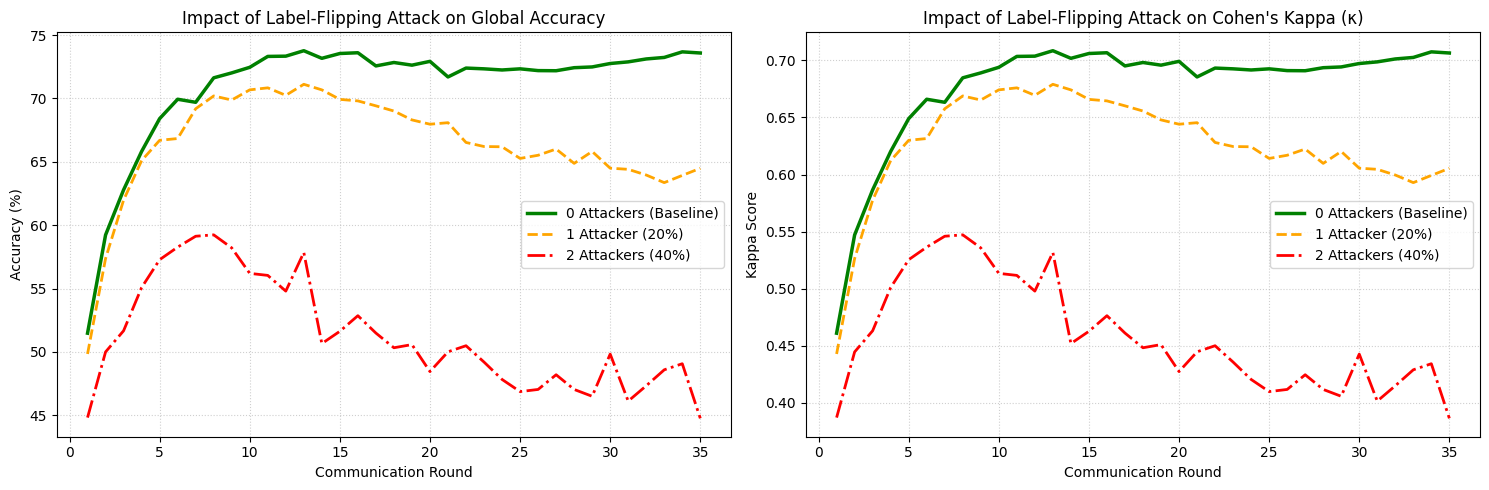

 SUMMARY TABLE (Part 2.1 Complete):
Configuration             | Accuracy   | F1-Score   | Kappa     
-----------------------------------------------------------------
0 Attackers (Baseline)    | 73.59%     | 0.7360     | 0.7066
1 Attacker                | 64.49%     | 0.6456     | 0.6054
2 Attackers               | 44.76%     | 0.4472     | 0.3862


In [11]:
# Comparison Plot: Baseline vs 1 Attacker vs 2 Attackers
rounds_bl = baseline_history["rounds"][1:]
acc_bl = [a * 100 for a in baseline_history["accuracy"][1:]]
f1_bl = baseline_history["f1"][1:]
kappa_bl = baseline_history["kappa"][1:]

rounds_a1 = attack_1_history["rounds"][1:]
acc_a1 = [a * 100 for a in attack_1_history["accuracy"][1:]]
f1_a1 = attack_1_history["f1"][1:]
kappa_a1 = attack_1_history["kappa"][1:]

rounds_a2 = attack_2_history["rounds"][1:]
acc_a2 = [a * 100 for a in attack_2_history["accuracy"][1:]]
f1_a2 = attack_2_history["f1"][1:]
kappa_a2 = attack_2_history["kappa"][1:]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Accuracy Comparison
ax1.plot(rounds_bl, acc_bl, label="0 Attackers (Baseline)", color="green", linewidth=2.5)
ax1.plot(rounds_a1, acc_a1, label="1 Attacker (20%)", color="orange", linestyle="--", linewidth=2)
ax1.plot(rounds_a2, acc_a2, label="2 Attackers (40%)", color="red", linestyle="-.", linewidth=2)
ax1.set_title("Impact of Label-Flipping Attack on Global Accuracy")
ax1.set_xlabel("Communication Round")
ax1.set_ylabel("Accuracy (%)")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend()

# Kappa Comparison
ax2.plot(rounds_bl, kappa_bl, label="0 Attackers (Baseline)", color="green", linewidth=2.5)
ax2.plot(rounds_a1, kappa_a1, label="1 Attacker (20%)", color="orange", linestyle="--", linewidth=2)
ax2.plot(rounds_a2, kappa_a2, label="2 Attackers (40%)", color="red", linestyle="-.", linewidth=2)
ax2.set_title("Impact of Label-Flipping Attack on Cohen's Kappa (κ)")
ax2.set_xlabel("Communication Round")
ax2.set_ylabel("Kappa Score")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

print(" SUMMARY TABLE (Part 2.1 Complete):")
print(f"{'Configuration':<25} | {'Accuracy':<10} | {'F1-Score':<10} | {'Kappa':<10}")
print("-" * 65)
print(f"{'0 Attackers (Baseline)':<25} | {acc_bl[-1]:.2f}%     | {f1_bl[-1]:.4f}     | {kappa_bl[-1]:.4f}")
print(f"{'1 Attacker':<25} | {acc_a1[-1]:.2f}%     | {f1_a1[-1]:.4f}     | {kappa_a1[-1]:.4f}")
print(f"{'2 Attackers':<25} | {acc_a2[-1]:.2f}%     | {f1_a2[-1]:.4f}     | {kappa_a2[-1]:.4f}")

In [12]:
# Storage for metrics: Defense 1 (FedMedian) with 0 Attackers
def1_0att_history = {
    "rounds": [],
    "loss": [],
    "accuracy": [],
    "f1": [],
    "kappa": []
}

def get_evaluate_fn_def1_0att():
    net = SimpleCNN().to(device)

    def evaluate(server_round: int, parameters: fl.common.NDArrays, config: dict):
        set_parameters(net, parameters)
        loss, acc, f1, kappa = evaluate_model(net, test_loader, device)

        def1_0att_history["rounds"].append(server_round)
        def1_0att_history["loss"].append(loss)
        def1_0att_history["accuracy"].append(acc)
        def1_0att_history["f1"].append(f1)
        def1_0att_history["kappa"].append(kappa)

        print(f" [Def1 | 0 Att] Round {server_round:02d} | Test Loss: {loss:.4f} | Acc: {acc*100:.2f}% | F1: {f1:.4f} | Kappa: {kappa:.4f}")
        return loss, {"accuracy": acc, "f1": f1, "kappa": kappa}

    return evaluate

# 1. Setup Robust Strategy: FedMedian (Coordinate-wise Median)
strategy_def1_0att = fl.server.strategy.FedMedian(
    fraction_fit=1.0,
    fraction_evaluate=0.0,
    min_fit_clients=5,
    min_available_clients=5,
    evaluate_fn=get_evaluate_fn_def1_0att(),
)

print("Starting 35-round Simulation: Defense 1 (FedMedian) with 0 Attackers...")
fl.simulation.start_simulation(
    client_fn=client_fn,  # All 5 clients are honest
    num_clients=5,
    config=fl.server.ServerConfig(num_rounds=35),
    strategy=strategy_def1_0att,
    client_resources={"num_cpus": 2, "num_gpus": 0.2 if torch.cuda.is_available() else 0.0}
)

print("\n Defense 1 (0 Attackers) Complete!")

	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
INFO :      Starting Flower simulation, config: num_rounds=35, no round_timeout


Starting 35-round Simulation: Defense 1 (FedMedian) with 0 Attackers...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
2026-11-08 20:12:30,680	INFO worker.py:2012 -- Started a local Ray instance.
INFO :      Flower VCE: Ray initialized with resources: {'CPU': 12.0, 'object_store_memory': 16946716262.0, 'accelerator_type:L4': 1.0, 'GPU': 1.0, 'node:__internal_head__': 1.0, 'node:172.28.0.12': 1.0, 'memory': 39542337946.0}
INFO :      Optimize your simulation with Flower VCE: https://flower.ai/docs/framework/how-to-run-simulations.html
INFO :      Flower VCE: Resources for each Virtual Client: {'num_cpus': 2, 'num_gpus': 0.2}
INFO :      Flower VCE: Creating VirtualClientEngineActorPool with 5 actors
INFO :      [INIT]
INFO :      Requesting initial parameters from one random client
(pid=2

 [Def1 | 0 Att] Round 00 | Test Loss: 2.3080 | Acc: 9.75% | F1: 0.0351 | Kappa: -0.0028


INFO :      aggregate_fit: received 5 results and 0 failures
INFO :      fit progress: (1, 1.4248597663879394, {'accuracy': np.float64(0.4869), 'f1': 0.4656412386375165, 'kappa': np.float64(0.42988888888888876)}, 10.189918431000024)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [ROUND 2]
INFO :      configure_fit: strategy sampled 5 clients (out of 5)


 [Def1 | 0 Att] Round 01 | Test Loss: 1.4249 | Acc: 48.69% | F1: 0.4656 | Kappa: 0.4299


... (65 outputs left out)

 [Def1 | 0 Att] Round 34 | Test Loss: 1.7831 | Acc: 73.23% | F1: 0.7322 | Kappa: 0.7026


INFO :      aggregate_fit: received 5 results and 0 failures
INFO :      fit progress: (35, 1.8365367721557617, {'accuracy': np.float64(0.7352), 'f1': 0.735107276148951, 'kappa': np.float64(0.7057777777777778)}, 200.04506407899999)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [SUMMARY]
INFO :      Run finished 35 round(s) in 200.05s
INFO :      	History (loss, centralized):
INFO :      		round 0: 2.3079822105407715
INFO :      		round 1: 1.4248597663879394
INFO :      		round 2: 1.1887529293060304
INFO :      		round 3: 1.0872545595169067
INFO :      		round 4: 0.9934013486862182
INFO :      		round 5: 0.93344517402648

 [Def1 | 0 Att] Round 35 | Test Loss: 1.8365 | Acc: 73.52% | F1: 0.7351 | Kappa: 0.7058

 Defense 1 (0 Attackers) Complete!


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [13]:
import flwr as fl
import torch
import gc
gc.collect()

# Storage for metrics: Defense 1 (FedMedian) with 1 Attacker
def1_1att_history = {
    "rounds": [],
    "loss": [],
    "accuracy": [],
    "f1": [],
    "kappa": []
}

def get_evaluate_fn_def1_1att():
    net = SimpleCNN().to(device)

    def evaluate(server_round: int, parameters: fl.common.NDArrays, config: dict):
        set_parameters(net, parameters)
        loss, acc, f1, kappa = evaluate_model(net, test_loader, device)

        def1_1att_history["rounds"].append(server_round)
        def1_1att_history["loss"].append(loss)
        def1_1att_history["accuracy"].append(acc)
        def1_1att_history["f1"].append(f1)
        def1_1att_history["kappa"].append(kappa)

        print(f" [Def1 | 1 Att] Round {server_round:02d} | Test Loss: {loss:.4f} | Acc: {acc*100:.2f}% | F1: {f1:.4f} | Kappa: {kappa:.4f}")
        return loss, {"accuracy": acc, "f1": f1, "kappa": kappa}

    return evaluate

# Setup Robust Strategy: FedMedian with 1 Attacker
strategy_def1_1att = fl.server.strategy.FedMedian(
    fraction_fit=1.0,
    fraction_evaluate=0.0,
    min_fit_clients=5,
    min_available_clients=5,
    evaluate_fn=get_evaluate_fn_def1_1att(),
)

print(" Starting 35-round Simulation: Defense 1 (FedMedian) with 1 Attacker...")
fl.simulation.start_simulation(
    client_fn=client_fn_1_attacker,  # Client 4 is the attacker
    num_clients=5,
    config=fl.server.ServerConfig(num_rounds=35),
    strategy=strategy_def1_1att,
    client_resources={"num_cpus": 2, "num_gpus": 0.2 if torch.cuda.is_available() else 0.0}
)

print("\n Defense 1 (1 Attacker) Complete!")

	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
INFO :      Starting Flower simulation, config: num_rounds=35, no round_timeout


 Starting 35-round Simulation: Defense 1 (FedMedian) with 1 Attacker...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
2026-11-08 20:16:14,347	INFO worker.py:2012 -- Started a local Ray instance.
INFO :      Flower VCE: Ray initialized with resources: {'CPU': 12.0, 'accelerator_type:L4': 1.0, 'object_store_memory': 16946851430.0, 'node:__internal_head__': 1.0, 'GPU': 1.0, 'node:172.28.0.12': 1.0, 'memory': 39542653338.0}
INFO :      Optimize your simulation with Flower VCE: https://flower.ai/docs/framework/how-to-run-simulations.html
INFO :      Flower VCE: Resources for each Virtual Client: {'num_cpus': 2, 'num_gpus': 0.2}
INFO :      Flower VCE: Creating VirtualClientEngineActorPool with 5 actors
INFO :      [INIT]
INFO :      Requesting initial parameters from one random client
(pid=2

 [Def1 | 1 Att] Round 00 | Test Loss: 2.3082 | Acc: 9.68% | F1: 0.0371 | Kappa: -0.0036


INFO :      aggregate_fit: received 5 results and 0 failures
INFO :      fit progress: (1, 1.5030283773422242, {'accuracy': np.float64(0.4797), 'f1': 0.4733840248414259, 'kappa': np.float64(0.421888888888889)}, 10.184596262000014)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [ROUND 2]
INFO :      configure_fit: strategy sampled 5 clients (out of 5)


 [Def1 | 1 Att] Round 01 | Test Loss: 1.5030 | Acc: 47.97% | F1: 0.4734 | Kappa: 0.4219


... (65 outputs left out)

 [Def1 | 1 Att] Round 34 | Test Loss: 1.7461 | Acc: 72.25% | F1: 0.7220 | Kappa: 0.6917


INFO :      aggregate_fit: received 5 results and 0 failures
INFO :      fit progress: (35, 1.803714221572876, {'accuracy': np.float64(0.7223), 'f1': 0.7220277079451402, 'kappa': np.float64(0.6914444444444445)}, 200.75071794699988)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [SUMMARY]
INFO :      Run finished 35 round(s) in 200.75s
INFO :      	History (loss, centralized):
INFO :      		round 0: 2.308208464050293
INFO :      		round 1: 1.5030283773422242
INFO :      		round 2: 1.2234208265304565
INFO :      		round 3: 1.1662876463890075
INFO :      		round 4: 1.0793976022720337
INFO :      		round 5: 1.028978443336486

 [Def1 | 1 Att] Round 35 | Test Loss: 1.8037 | Acc: 72.23% | F1: 0.7220 | Kappa: 0.6914

 Defense 1 (1 Attacker) Complete!


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [15]:
import flwr as fl
import torch
import gc

gc.collect()

# Storage for Def1: Defense 1 (FedMedian) with 2 Attackers
def1_2att_history = {
    "round": [],
    "loss": [],
    "accuracy": [],
    "f1": [],
    "kappa": []
}

def get_evaluate_fn_def1_2att():
    net = SimpleCNN().to(device)

    def evaluate(server_round: int, parameters: fl.common.NDArrays, config: dict):
        set_parameters(net, parameters)
        loss, acc, f1, kappa = evaluate_model(net, test_loader, device)

        def1_2att_history["round"].append(server_round)
        def1_2att_history["loss"].append(loss)
        def1_2att_history["accuracy"].append(acc)
        def1_2att_history["f1"].append(f1)
        def1_2att_history["kappa"].append(kappa)

        print(f"[Def1 | 2 Att] Round {server_round:02d} | Test Loss: {loss:.4f} | Acc: {acc*100:.2f}% | F1: {f1:.4f} | Kappa: {kappa:.4f}")
        return loss, {"accuracy": acc, "f1": f1, "kappa": kappa}

    return evaluate

# Setup Robust Strategy: FedMedian with 2 Attackers
strategy_def1_2att = fl.server.strategy.FedMedian(
    fraction_fit=1.0,
    fraction_evaluate=0.0,
    min_fit_clients=5,
    min_available_clients=5,
    evaluate_fn=get_evaluate_fn_def1_2att(),
)

print("Starting 35-round Simulation: Defense 1 (FedMedian) with 2 Attackers...")
fl.simulation.start_simulation(
    client_fn=client_fn_2_attackers,  # Clients 3 and 4 are malicious
    num_clients=5,
    config=fl.server.ServerConfig(num_rounds=35),
    strategy=strategy_def1_2att,
    client_resources={"num_cpus": 2, "num_gpus": 0.2 if torch.cuda.is_available() else 0.0}
)

print("Defense 1 (2 Attackers) Complete.")

	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
INFO :      Starting Flower simulation, config: num_rounds=35, no round_timeout


Starting 35-round Simulation: Defense 1 (FedMedian) with 2 Attackers...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
2026-11-08 20:23:34,565	INFO worker.py:2012 -- Started a local Ray instance.
INFO :      Flower VCE: Ray initialized with resources: {'CPU': 12.0, 'node:__internal_head__': 1.0, 'accelerator_type:L4': 1.0, 'GPU': 1.0, 'object_store_memory': 16948077772.0, 'node:172.28.0.12': 1.0, 'memory': 39545514804.0}
INFO :      Optimize your simulation with Flower VCE: https://flower.ai/docs/framework/how-to-run-simulations.html
INFO :      Flower VCE: Resources for each Virtual Client: {'num_cpus': 2, 'num_gpus': 0.2}
INFO :      Flower VCE: Creating VirtualClientEngineActorPool with 5 actors
INFO :      [INIT]
INFO :      Requesting initial parameters from one random client
(pid=2

[Def1 | 2 Att] Round 00 | Test Loss: 2.3055 | Acc: 11.06% | F1: 0.0526 | Kappa: 0.0118


INFO :      aggregate_fit: received 5 results and 0 failures
INFO :      fit progress: (1, 1.6699980030059813, {'accuracy': np.float64(0.4185), 'f1': 0.4039465353158747, 'kappa': np.float64(0.35388888888888903)}, 10.005617739000172)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [ROUND 2]
INFO :      configure_fit: strategy sampled 5 clients (out of 5)


[Def1 | 2 Att] Round 01 | Test Loss: 1.6700 | Acc: 41.85% | F1: 0.4039 | Kappa: 0.3539


... (65 outputs left out)

[Def1 | 2 Att] Round 34 | Test Loss: 1.6681 | Acc: 58.96% | F1: 0.5891 | Kappa: 0.5440


INFO :      aggregate_fit: received 5 results and 0 failures
INFO :      fit progress: (35, 1.7746360404968262, {'accuracy': np.float64(0.5967), 'f1': 0.5957760285454808, 'kappa': np.float64(0.551888888888889)}, 198.54851747300017)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [SUMMARY]
INFO :      Run finished 35 round(s) in 198.55s
INFO :      	History (loss, centralized):
INFO :      		round 0: 2.3054535133361815
INFO :      		round 1: 1.6699980030059813
INFO :      		round 2: 1.386609162902832
INFO :      		round 3: 1.3395690223693848
INFO :      		round 4: 1.298390599822998
INFO :      		round 5: 1.2429501752853394

[Def1 | 2 Att] Round 35 | Test Loss: 1.7746 | Acc: 59.67% | F1: 0.5958 | Kappa: 0.5519
Defense 1 (2 Attackers) Complete.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


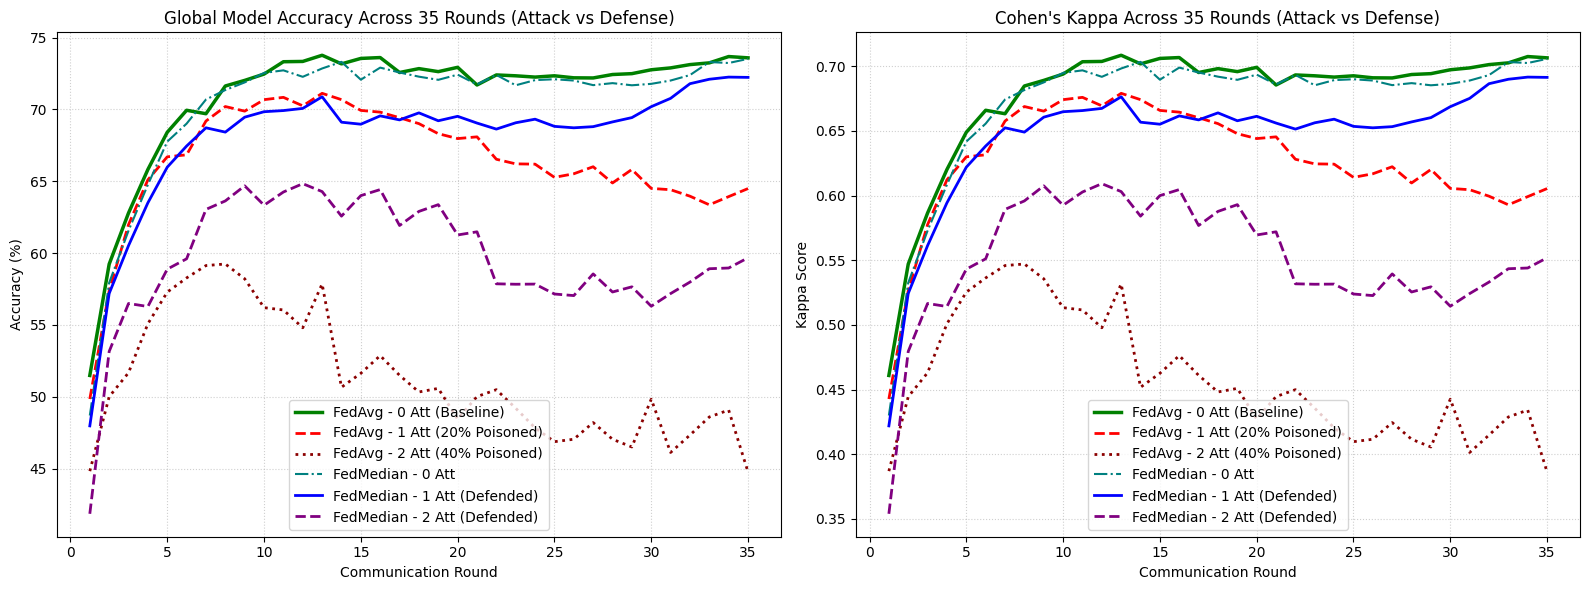

Strategy     | Partition  | Attackers  | Defense      | Accuracy   | F1-Score   | Kappa     
FedAvg       | IID        | 0          | None         | 73.59%     | 0.7360     | 0.7066
FedAvg       | IID        | 1          | None         | 64.49%     | 0.6456     | 0.6054
FedAvg       | IID        | 2          | None         | 44.76%     | 0.4472     | 0.3862
FedAvg       | IID        | 0          | FedMedian    | 73.52%     | 0.7351     | 0.7058
FedAvg       | IID        | 1          | FedMedian    | 72.23%     | 0.7220     | 0.6914
FedAvg       | IID        | 2          | FedMedian    | 59.67%     | 0.5958     | 0.5519


In [16]:
import matplotlib.pyplot as plt

# Extract rounds and metrics (ignoring round 0 pre-training)
r_bl = baseline_history.get("rounds", baseline_history.get("round"))[1:]
acc_bl = [a * 100 for a in baseline_history["accuracy"][1:]]
f1_bl = baseline_history["f1"][1:]
kappa_bl = baseline_history["kappa"][1:]

r_a1 = attack_1_history.get("rounds", attack_1_history.get("round"))[1:]
acc_a1 = [a * 100 for a in attack_1_history["accuracy"][1:]]
f1_a1 = attack_1_history["f1"][1:]
kappa_a1 = attack_1_history["kappa"][1:]

r_a2 = attack_2_history.get("rounds", attack_2_history.get("round"))[1:]
acc_a2 = [a * 100 for a in attack_2_history["accuracy"][1:]]
f1_a2 = attack_2_history["f1"][1:]
kappa_a2 = attack_2_history["kappa"][1:]

r_d0 = def1_0att_history.get("rounds", def1_0att_history.get("round"))[1:]
acc_d0 = [a * 100 for a in def1_0att_history["accuracy"][1:]]
f1_d0 = def1_0att_history["f1"][1:]
kappa_d0 = def1_0att_history["kappa"][1:]

r_d1 = def1_1att_history.get("rounds", def1_1att_history.get("round"))[1:]
acc_d1 = [a * 100 for a in def1_1att_history["accuracy"][1:]]
f1_d1 = def1_1att_history["f1"][1:]
kappa_d1 = def1_1att_history["kappa"][1:]

r_d2 = def1_2att_history.get("rounds", def1_2att_history.get("round"))[1:]
acc_d2 = [a * 100 for a in def1_2att_history["accuracy"][1:]]
f1_d2 = def1_2att_history["f1"][1:]
kappa_d2 = def1_2att_history["kappa"][1:]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Global Accuracy Comparison
ax1.plot(r_bl, acc_bl, label="FedAvg - 0 Att (Baseline)", color="green", linewidth=2.5)
ax1.plot(r_a1, acc_a1, label="FedAvg - 1 Att (20% Poisoned)", color="red", linestyle="--", linewidth=2)
ax1.plot(r_a2, acc_a2, label="FedAvg - 2 Att (40% Poisoned)", color="darkred", linestyle=":", linewidth=2)
ax1.plot(r_d0, acc_d0, label="FedMedian - 0 Att", color="teal", linestyle="-.", linewidth=1.5)
ax1.plot(r_d1, acc_d1, label="FedMedian - 1 Att (Defended)", color="blue", linewidth=2)
ax1.plot(r_d2, acc_d2, label="FedMedian - 2 Att (Defended)", color="purple", linestyle="--", linewidth=2)
ax1.set_title("Global Model Accuracy Across 35 Rounds (Attack vs Defense)")
ax1.set_xlabel("Communication Round")
ax1.set_ylabel("Accuracy (%)")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend()

# Plot 2: Cohen's Kappa Comparison
ax2.plot(r_bl, kappa_bl, label="FedAvg - 0 Att (Baseline)", color="green", linewidth=2.5)
ax2.plot(r_a1, kappa_a1, label="FedAvg - 1 Att (20% Poisoned)", color="red", linestyle="--", linewidth=2)
ax2.plot(r_a2, kappa_a2, label="FedAvg - 2 Att (40% Poisoned)", color="darkred", linestyle=":", linewidth=2)
ax2.plot(r_d0, kappa_d0, label="FedMedian - 0 Att", color="teal", linestyle="-.", linewidth=1.5)
ax2.plot(r_d1, kappa_d1, label="FedMedian - 1 Att (Defended)", color="blue", linewidth=2)
ax2.plot(r_d2, kappa_d2, label="FedMedian - 2 Att (Defended)", color="purple", linestyle="--", linewidth=2)
ax2.set_title("Cohen's Kappa Across 35 Rounds (Attack vs Defense)")
ax2.set_xlabel("Communication Round")
ax2.set_ylabel("Kappa Score")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.savefig("part2_attack_vs_defense_comparison.png", dpi=300)
plt.show()

# Print Table 1
print("=" * 80)
print(f"{'Strategy':<12} | {'Partition':<10} | {'Attackers':<10} | {'Defense':<12} | {'Accuracy':<10} | {'F1-Score':<10} | {'Kappa':<10}")
print("=" * 80)
print(f"{'FedAvg':<12} | {'IID':<10} | {'0':<10} | {'None':<12} | {acc_bl[-1]:.2f}%     | {f1_bl[-1]:.4f}     | {kappa_bl[-1]:.4f}")
print(f"{'FedAvg':<12} | {'IID':<10} | {'1':<10} | {'None':<12} | {acc_a1[-1]:.2f}%     | {f1_a1[-1]:.4f}     | {kappa_a1[-1]:.4f}")
print(f"{'FedAvg':<12} | {'IID':<10} | {'2':<10} | {'None':<12} | {acc_a2[-1]:.2f}%     | {f1_a2[-1]:.4f}     | {kappa_a2[-1]:.4f}")
print(f"{'FedAvg':<12} | {'IID':<10} | {'0':<10} | {'FedMedian':<12} | {acc_d0[-1]:.2f}%     | {f1_d0[-1]:.4f}     | {kappa_d0[-1]:.4f}")
print(f"{'FedAvg':<12} | {'IID':<10} | {'1':<10} | {'FedMedian':<12} | {acc_d1[-1]:.2f}%     | {f1_d1[-1]:.4f}     | {kappa_d1[-1]:.4f}")
print(f"{'FedAvg':<12} | {'IID':<10} | {'2':<10} | {'FedMedian':<12} | {acc_d2[-1]:.2f}%     | {f1_d2[-1]:.4f}     | {kappa_d2[-1]:.4f}")
print("=" * 80)

In [18]:
import flwr as fl
import torch
import gc

gc.collect()

# Storage for Part 2.3: Alternative 1 (FedAvgM) with 0 Attackers
fedavgm_0att_history = {
    "rounds": [],
    "loss": [],
    "accuracy": [],
    "f1": [],
    "kappa": []
}

def get_evaluate_fn_fedavgm_0att():
    net = SimpleCNN().to(device)

    def evaluate(server_round: int, parameters: fl.common.NDArrays, config: dict):
        set_parameters(net, parameters)
        loss, acc, f1, kappa = evaluate_model(net, test_loader, device)

        fedavgm_0att_history["rounds"].append(server_round)
        fedavgm_0att_history["loss"].append(loss)
        fedavgm_0att_history["accuracy"].append(acc)
        fedavgm_0att_history["f1"].append(f1)
        fedavgm_0att_history["kappa"].append(kappa)

        print(f"[FedAvgM | 0 Att] Round {server_round:02d} | Test Loss: {loss:.4f} | Acc: {acc*100:.2f}% | F1: {f1:.4f} | Kappa: {kappa:.4f}")
        return loss, {"accuracy": acc, "f1": f1, "kappa": kappa}

    return evaluate

# Initial model parameters needed for server-side momentum
initial_model = SimpleCNN()
initial_parameters = fl.common.ndarrays_to_parameters(get_parameters(initial_model))

# Setup Strategy: FedAvgM (Server Momentum = 0.9)
strategy_fedavgm_0att = fl.server.strategy.FedAvgM(
    fraction_fit=1.0,
    fraction_evaluate=0.0,
    min_fit_clients=5,
    min_available_clients=5,
    evaluate_fn=get_evaluate_fn_fedavgm_0att(),
    initial_parameters=initial_parameters,
    server_momentum=0.9,
    server_learning_rate=1.0,
)

print("Starting 35-round Simulation: Part 2.3 Alternative 1 (FedAvgM) with 0 Attackers...")
fl.simulation.start_simulation(
    client_fn=client_fn,  # 5 honest clients
    num_clients=5,
    config=fl.server.ServerConfig(num_rounds=35),
    strategy=strategy_fedavgm_0att,
    client_resources={"num_cpus": 2, "num_gpus": 0.2 if torch.cuda.is_available() else 0.0}
)

print("Part 2.3 (FedAvgM 0 Attackers) Complete.")

	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
INFO :      Starting Flower simulation, config: num_rounds=35, no round_timeout


Starting 35-round Simulation: Part 2.3 Alternative 1 (FedAvgM) with 0 Attackers...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
2026-11-08 20:50:40,252	INFO worker.py:2012 -- Started a local Ray instance.
INFO :      Flower VCE: Ray initialized with resources: {'CPU': 12.0, 'node:__internal_head__': 1.0, 'object_store_memory': 16947685785.0, 'accelerator_type:L4': 1.0, 'GPU': 1.0, 'node:172.28.0.12': 1.0, 'memory': 39544600167.0}
INFO :      Optimize your simulation with Flower VCE: https://flower.ai/docs/framework/how-to-run-simulations.html
INFO :      Flower VCE: Resources for each Virtual Client: {'num_cpus': 2, 'num_gpus': 0.2}
INFO :      Flower VCE: Creating VirtualClientEngineActorPool with 5 actors
INFO :      [INIT]
INFO :      Using initial global parameters provided by strategy
INFO :

[FedAvgM | 0 Att] Round 00 | Test Loss: 2.3062 | Acc: 10.72% | F1: 0.0442 | Kappa: 0.0080


INFO :      aggregate_fit: received 5 results and 0 failures
INFO :      fit progress: (1, 1.4313180961608887, {'accuracy': np.float64(0.4943), 'f1': 0.48140357890579316, 'kappa': np.float64(0.4381111111111111)}, 13.633782523999798)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [ROUND 2]
INFO :      configure_fit: strategy sampled 5 clients (out of 5)


[FedAvgM | 0 Att] Round 01 | Test Loss: 1.4313 | Acc: 49.43% | F1: 0.4814 | Kappa: 0.4381


... (65 outputs left out)

[FedAvgM | 0 Att] Round 34 | Test Loss: 3.8728 | Acc: 57.70% | F1: 0.5809 | Kappa: 0.5300


INFO :      aggregate_fit: received 5 results and 0 failures
INFO :      fit progress: (35, 3.5851434272766114, {'accuracy': np.float64(0.5697), 'f1': 0.5793005205242363, 'kappa': np.float64(0.5218888888888888)}, 204.06305118899945)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [SUMMARY]
INFO :      Run finished 35 round(s) in 204.06s
INFO :      	History (loss, centralized):
INFO :      		round 0: 2.3061588638305666
INFO :      		round 1: 1.4313180961608887
INFO :      		round 2: 2.5149085960388184
INFO :      		round 3: 2.2571887405395508
INFO :      		round 4: 1.2796475656509398
INFO :      		round 5: 1.1207991760253

[FedAvgM | 0 Att] Round 35 | Test Loss: 3.5851 | Acc: 56.97% | F1: 0.5793 | Kappa: 0.5219
Part 2.3 (FedAvgM 0 Attackers) Complete.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [20]:
# ==============================================================================
# CELL 17: Part 2.3 - FedAvgM with 1 Attacker (20% Poisoned)
# Fully self-contained
# ==============================================================================

import flwr as fl
import numpy as np
import torch
from flwr.common import ndarrays_to_parameters

print("Starting Part 2.3: FedAvgM with 1 Attacker...")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Self-contained dynamic client generator
def get_client_fn_dynamic(num_attackers: int):
    def client_fn(context: fl.common.Context) -> fl.client.Client:
        cid = int(context.node_config["partition-id"])
        if num_attackers == 1 and cid == 4:
            return MaliciousFlowerClient(cid, client_datasets[cid]).to_client()
        elif num_attackers == 2 and cid in [3, 4]:
            return MaliciousFlowerClient(cid, client_datasets[cid]).to_client()
        else:
            return FlowerClient(cid, client_datasets[cid]).to_client()
    return client_fn

# Initial parameters required by FedAvgM
initial_model = SimpleCNN().to(device)
initial_ndarrays = get_parameters(initial_model)
initial_parameters = ndarrays_to_parameters(initial_ndarrays)

# Storage for metrics
fedavgm_1att_history = {
    "rounds": [],
    "loss": [],
    "accuracy": [],
    "f1": [],
    "kappa": []
}

def get_evaluate_fn_m1():
    net = SimpleCNN().to(device)
    def evaluate(server_round: int, parameters: fl.common.NDArrays, config: dict):
        set_parameters(net, parameters)
        loss, acc, f1, kappa = evaluate_model(net, test_loader, device)
        fedavgm_1att_history["rounds"].append(server_round)
        fedavgm_1att_history["loss"].append(loss)
        fedavgm_1att_history["accuracy"].append(acc)
        fedavgm_1att_history["f1"].append(f1)
        fedavgm_1att_history["kappa"].append(kappa)
        if server_round % 5 == 0 or server_round == 35:
            print(f"[FedAvgM | 1 Att] Round {server_round:02d} | Loss: {loss:.4f} | Acc: {acc*100:.2f}% | F1: {f1:.4f} | Kappa: {kappa:.4f}")
        return loss, {"accuracy": acc, "f1": f1, "kappa": kappa}
    return evaluate

# Setup FedAvgM strategy
strategy_m1 = fl.server.strategy.FedAvgM(
    fraction_fit=1.0,
    min_fit_clients=5,
    min_available_clients=5,
    fraction_evaluate=0.0,
    evaluate_fn=get_evaluate_fn_m1(),
    initial_parameters=initial_parameters,
    server_learning_rate=1.0,
    server_momentum=0.9
)

print("\n" + "="*70)
print("Starting 35-round Simulation: FedAvgM with 1 Attacker (20% Poisoned)...")
print("="*70)

fl.simulation.start_simulation(
    client_fn=get_client_fn_dynamic(num_attackers=1),
    num_clients=5,
    config=fl.server.ServerConfig(num_rounds=35),
    strategy=strategy_m1,
    client_resources={"num_cpus": 2, "num_gpus": 0.2 if torch.cuda.is_available() else 0.0}
)

print("\n" + "="*70)
print("Part 2.3 (FedAvgM with 1 Attacker) Complete!")
print(f"Final Round 35 -> Acc: {fedavgm_1att_history['accuracy'][-1]*100:.2f}% | F1: {fedavgm_1att_history['f1'][-1]:.4f} | Kappa: {fedavgm_1att_history['kappa'][-1]:.4f} | Loss: {fedavgm_1att_history['loss'][-1]:.4f}")
print("="*70)

	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
INFO :      Starting Flower simulation, config: num_rounds=35, no round_timeout


Starting Part 2.3: FedAvgM with 1 Attacker...

Starting 35-round Simulation: FedAvgM with 1 Attacker (20% Poisoned)...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
2026-11-08 21:00:59,968	INFO worker.py:2012 -- Started a local Ray instance.
INFO :      Flower VCE: Ray initialized with resources: {'CPU': 12.0, 'node:__internal_head__': 1.0, 'accelerator_type:L4': 1.0, 'object_store_memory': 16947358924.0, 'node:172.28.0.12': 1.0, 'GPU': 1.0, 'memory': 39543837492.0}
INFO :      Optimize your simulation with Flower VCE: https://flower.ai/docs/framework/how-to-run-simulations.html
INFO :      Flower VCE: Resources for each Virtual Client: {'num_cpus': 2, 'num_gpus': 0.2}
INFO :      Flower VCE: Creating VirtualClientEngineActorPool with 5 actors
INFO :      [INIT]
INFO :      Using initial global parameters provided by strategy
INFO :

[FedAvgM | 1 Att] Round 00 | Loss: 2.3040 | Acc: 13.74% | F1: 0.0788 | Kappa: 0.0416


INFO :      aggregate_fit: received 5 results and 0 failures
INFO :      fit progress: (1, 1.5170098987579346, {'accuracy': np.float64(0.4831), 'f1': 0.46598866232313474, 'kappa': np.float64(0.42566666666666686)}, 14.033033152000826)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [ROUND 2]
INFO :      configure_fit: strategy sampled 5 clients (out of 5)
INFO :      aggregate_fit: received 5 results and 0 failures
INFO :      fit progress: (2, 2.054425833892822, {'accuracy': np.float64(0.5175), 'f1': 0.5117319650310331, 'kappa': np.float64(0.463888888888889)}, 19.860834217000047)
/usr/local/lib/python3.13/dist-packages/ju

[FedAvgM | 1 Att] Round 05 | Loss: 1.1889 | Acc: 58.74% | F1: 0.5857 | Kappa: 0.5416


... (9 outputs left out)

[FedAvgM | 1 Att] Round 30 | Loss: 3.3999 | Acc: 49.93% | F1: 0.5029 | Kappa: 0.4437


INFO :      aggregate_fit: received 5 results and 0 failures
INFO :      fit progress: (31, 3.672002995300293, {'accuracy': np.float64(0.508), 'f1': 0.5115252607329065, 'kappa': np.float64(0.45333333333333337)}, 181.93094296000072)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [ROUND 32]
INFO :      configure_fit: strategy sampled 5 clients (out of 5)
INFO :      aggregate_fit: received 5 results and 0 failures
INFO :      fit progress: (32, 3.3233401012420654, {'accuracy': np.float64(0.5462), 'f1': 0.5488049904481694, 'kappa': np.float64(0.49577777777777776)}, 187.68093089400008)
/usr/local/lib/python3.13/dist-packages

[FedAvgM | 1 Att] Round 35 | Loss: 3.3812 | Acc: 49.32% | F1: 0.4984 | Kappa: 0.4369

Part 2.3 (FedAvgM with 1 Attacker) Complete!
Final Round 35 -> Acc: 49.32% | F1: 0.4984 | Kappa: 0.4369 | Loss: 3.3812


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [21]:
# ==============================================================================
# CELL 18: Part 2.4 - Second Defense: FedTrimmedAvg (Coordinate-wise Trimmed Mean)
# Grade A Requirement: Robust Defense Comparison (beta = 0.2)
# ==============================================================================

import flwr as fl
import numpy as np
import torch
from flwr.common import ndarrays_to_parameters

print("Starting Part 2.4: FedTrimmedAvg Experiments (Grade A Defense)...")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Storage for Trimmed Mean metrics
trimmed_0att_history = {"rounds": [], "loss": [], "accuracy": [], "f1": [], "kappa": []}
trimmed_1att_history = {"rounds": [], "loss": [], "accuracy": [], "f1": [], "kappa": []}

def get_evaluate_fn_trimmed0():
    net = SimpleCNN().to(device)
    def evaluate(server_round: int, parameters: fl.common.NDArrays, config: dict):
        set_parameters(net, parameters)
        loss, acc, f1, kappa = evaluate_model(net, test_loader, device)
        trimmed_0att_history["rounds"].append(server_round)
        trimmed_0att_history["loss"].append(loss)
        trimmed_0att_history["accuracy"].append(acc)
        trimmed_0att_history["f1"].append(f1)
        trimmed_0att_history["kappa"].append(kappa)
        if server_round % 5 == 0 or server_round == 35:
            print(f"[FedTrimmedAvg | 0 Att] Round {server_round:02d} | Loss: {loss:.4f} | Acc: {acc*100:.2f}% | F1: {f1:.4f} | Kappa: {kappa:.4f}")
        return loss, {"accuracy": acc, "f1": f1, "kappa": kappa}
    return evaluate

def get_evaluate_fn_trimmed1():
    net = SimpleCNN().to(device)
    def evaluate(server_round: int, parameters: fl.common.NDArrays, config: dict):
        set_parameters(net, parameters)
        loss, acc, f1, kappa = evaluate_model(net, test_loader, device)
        trimmed_1att_history["rounds"].append(server_round)
        trimmed_1att_history["loss"].append(loss)
        trimmed_1att_history["accuracy"].append(acc)
        trimmed_1att_history["f1"].append(f1)
        trimmed_1att_history["kappa"].append(kappa)
        if server_round % 5 == 0 or server_round == 35:
            print(f"[FedTrimmedAvg | 1 Att] Round {server_round:02d} | Loss: {loss:.4f} | Acc: {acc*100:.2f}% | F1: {f1:.4f} | Kappa: {kappa:.4f}")
        return loss, {"accuracy": acc, "f1": f1, "kappa": kappa}
    return evaluate

# ------------------------------------------------------------------------------
# 1. FedTrimmedAvg with 0 Attackers (Baseline behavior)
# ------------------------------------------------------------------------------
print("\n" + "="*70)
print("Running Simulation: FedTrimmedAvg with 0 Attackers (beta = 0.2)...")
print("="*70)

strategy_trimmed_0 = fl.server.strategy.FedTrimmedAvg(
    fraction_fit=1.0,
    min_fit_clients=5,
    min_available_clients=5,
    fraction_evaluate=0.0,
    evaluate_fn=get_evaluate_fn_trimmed0(),
    beta=0.2
)

fl.simulation.start_simulation(
    client_fn=get_client_fn_dynamic(num_attackers=0),
    num_clients=5,
    config=fl.server.ServerConfig(num_rounds=35),
    strategy=strategy_trimmed_0,
    client_resources={"num_cpus": 2, "num_gpus": 0.2 if torch.cuda.is_available() else 0.0}
)

# ------------------------------------------------------------------------------
# 2. FedTrimmedAvg with 1 Attacker (20% Poisoned)
# ------------------------------------------------------------------------------
print("\n" + "="*70)
print("Running Simulation: FedTrimmedAvg with 1 Attacker (beta = 0.2)...")
print("="*70)

strategy_trimmed_1 = fl.server.strategy.FedTrimmedAvg(
    fraction_fit=1.0,
    min_fit_clients=5,
    min_available_clients=5,
    fraction_evaluate=0.0,
    evaluate_fn=get_evaluate_fn_trimmed1(),
    beta=0.2
)

fl.simulation.start_simulation(
    client_fn=get_client_fn_dynamic(num_attackers=1),
    num_clients=5,
    config=fl.server.ServerConfig(num_rounds=35),
    strategy=strategy_trimmed_1,
    client_resources={"num_cpus": 2, "num_gpus": 0.2 if torch.cuda.is_available() else 0.0}
)

print("\n" + "="*70)
print("Part 2.4 (FedTrimmedAvg: 0 & 1 Attacker) Complete!")
print(f"FedTrimmedAvg 0 Att Round 35 -> Acc: {trimmed_0att_history['accuracy'][-1]*100:.2f}% | F1: {trimmed_0att_history['f1'][-1]:.4f} | Kappa: {trimmed_0att_history['kappa'][-1]:.4f}")
print(f"FedTrimmedAvg 1 Att Round 35 -> Acc: {trimmed_1att_history['accuracy'][-1]*100:.2f}% | F1: {trimmed_1att_history['f1'][-1]:.4f} | Kappa: {trimmed_1att_history['kappa'][-1]:.4f}")
print("="*70)


	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
INFO :      Starting Flower simulation, config: num_rounds=35, no round_timeout


Starting Part 2.4: FedTrimmedAvg Experiments (Grade A Defense)...

Running Simulation: FedTrimmedAvg with 0 Attackers (beta = 0.2)...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
2026-11-08 21:06:04,570	INFO worker.py:2012 -- Started a local Ray instance.
INFO :      Flower VCE: Ray initialized with resources: {'CPU': 12.0, 'object_store_memory': 16945610342.0, 'node:__internal_head__': 1.0, 'accelerator_type:L4': 1.0, 'GPU': 1.0, 'node:172.28.0.12': 1.0, 'memory': 39539757466.0}
INFO :      Optimize your simulation with Flower VCE: https://flower.ai/docs/framework/how-to-run-simulations.html
INFO :      Flower VCE: Resources for each Virtual Client: {'num_cpus': 2, 'num_gpus': 0.2}
INFO :      Flower VCE: Creating VirtualClientEngineActorPool with 5 actors
INFO :      [INIT]
INFO :      Requesting initial parameters from one random client
(pid=4

[FedTrimmedAvg | 0 Att] Round 00 | Loss: 2.3042 | Acc: 10.33% | F1: 0.0382 | Kappa: 0.0037


INFO :      aggregate_fit: received 5 results and 0 failures
INFO :      fit progress: (1, 1.4059750633239747, {'accuracy': np.float64(0.4979), 'f1': 0.4812700930984067, 'kappa': np.float64(0.4421111111111111)}, 10.568911270000171)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [ROUND 2]
INFO :      configure_fit: strategy sampled 5 clients (out of 5)
INFO :      aggregate_fit: received 5 results and 0 failures
INFO :      fit progress: (2, 1.1886688495635986, {'accuracy': np.float64(0.5815), 'f1': 0.5747334201688511, 'kappa': np.float64(0.5349999999999998)}, 16.305360045999805)
/usr/local/lib/python3.13/dist-packages/ju

[FedTrimmedAvg | 0 Att] Round 05 | Loss: 0.9487 | Acc: 67.11% | F1: 0.6661 | Kappa: 0.6346


... (25 outputs left out)

[FedTrimmedAvg | 1 Att] Round 30 | Loss: 1.3402 | Acc: 70.25% | F1: 0.7029 | Kappa: 0.6694


INFO :      aggregate_fit: received 5 results and 0 failures
INFO :      fit progress: (31, 1.4529687457084657, {'accuracy': np.float64(0.7087), 'f1': 0.7085985835921301, 'kappa': np.float64(0.6763333333333332)}, 179.54103195199968)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [ROUND 32]
INFO :      configure_fit: strategy sampled 5 clients (out of 5)
INFO :      aggregate_fit: received 5 results and 0 failures
INFO :      fit progress: (32, 1.5782765951156617, {'accuracy': np.float64(0.7209), 'f1': 0.7205656027943688, 'kappa': np.float64(0.689888888888889)}, 185.08519179999985)
/usr/local/lib/python3.13/dist-packages/

[FedTrimmedAvg | 1 Att] Round 35 | Loss: 1.7818 | Acc: 72.32% | F1: 0.7230 | Kappa: 0.6924

Part 2.4 (FedTrimmedAvg: 0 & 1 Attacker) Complete!
FedTrimmedAvg 0 Att Round 35 -> Acc: 73.31% | F1: 0.7329 | Kappa: 0.7034
FedTrimmedAvg 1 Att Round 35 -> Acc: 72.32% | F1: 0.7230 | Kappa: 0.6924


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [22]:
# ==============================================================================
# CELL 19: Part 2.4 - FedTrimmedAvg with 2 Attackers (40% Poisoned)
# Final simulation for the Grade A defense study
# ==============================================================================

import flwr as fl
import numpy as np
import torch

print("Starting Final Simulation: FedTrimmedAvg with 2 Attackers (40% Poisoned)...")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

trimmed_2att_history = {
    "rounds": [],
    "loss": [],
    "accuracy": [],
    "f1": [],
    "kappa": []
}

def get_evaluate_fn_trimmed2():
    net = SimpleCNN().to(device)
    def evaluate(server_round: int, parameters: fl.common.NDArrays, config: dict):
        set_parameters(net, parameters)
        loss, acc, f1, kappa = evaluate_model(net, test_loader, device)
        trimmed_2att_history["rounds"].append(server_round)
        trimmed_2att_history["loss"].append(loss)
        trimmed_2att_history["accuracy"].append(acc)
        trimmed_2att_history["f1"].append(f1)
        trimmed_2att_history["kappa"].append(kappa)
        if server_round % 5 == 0 or server_round == 35:
            print(f"[FedTrimmedAvg | 2 Att] Round {server_round:02d} | Loss: {loss:.4f} | Acc: {acc*100:.2f}% | F1: {f1:.4f} | Kappa: {kappa:.4f}")
        return loss, {"accuracy": acc, "f1": f1, "kappa": kappa}
    return evaluate

strategy_trimmed_2 = fl.server.strategy.FedTrimmedAvg(
    fraction_fit=1.0,
    min_fit_clients=5,
    min_available_clients=5,
    fraction_evaluate=0.0,
    evaluate_fn=get_evaluate_fn_trimmed2(),
    beta=0.2
)

print("\n" + "="*70)
print("Running 35-round Simulation: FedTrimmedAvg with 2 Attackers...")
print("="*70)

fl.simulation.start_simulation(
    client_fn=get_client_fn_dynamic(num_attackers=2),
    num_clients=5,
    config=fl.server.ServerConfig(num_rounds=35),
    strategy=strategy_trimmed_2,
    client_resources={"num_cpus": 2, "num_gpus": 0.2 if torch.cuda.is_available() else 0.0}
)

print("\n" + "="*70)
print("ALL FL EXPERIMENTS ARE 100% COMPLETE!")
print(f"FedTrimmedAvg 2 Att Round 35 -> Acc: {trimmed_2att_history['accuracy'][-1]*100:.2f}% | F1: {trimmed_2att_history['f1'][-1]:.4f} | Kappa: {trimmed_2att_history['kappa'][-1]:.4f} | Loss: {trimmed_2att_history['loss'][-1]:.4f}")
print("="*70)

	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
INFO :      Starting Flower simulation, config: num_rounds=35, no round_timeout


Starting Final Simulation: FedTrimmedAvg with 2 Attackers (40% Poisoned)...

Running 35-round Simulation: FedTrimmedAvg with 2 Attackers...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
2026-11-08 21:16:06,699	INFO worker.py:2012 -- Started a local Ray instance.
INFO :      Flower VCE: Ray initialized with resources: {'CPU': 12.0, 'object_store_memory': 16946311987.0, 'node:__internal_head__': 1.0, 'accelerator_type:L4': 1.0, 'GPU': 1.0, 'node:172.28.0.12': 1.0, 'memory': 39541394637.0}
INFO :      Optimize your simulation with Flower VCE: https://flower.ai/docs/framework/how-to-run-simulations.html
INFO :      Flower VCE: Resources for each Virtual Client: {'num_cpus': 2, 'num_gpus': 0.2}
INFO :      Flower VCE: Creating VirtualClientEngineActorPool with 5 actors
INFO :      [INIT]
INFO :      Requesting initial parameters from one random client
(pid=5

[FedTrimmedAvg | 2 Att] Round 00 | Loss: 2.3112 | Acc: 11.35% | F1: 0.0401 | Kappa: 0.0150


INFO :      aggregate_fit: received 5 results and 0 failures
INFO :      fit progress: (1, 1.6901360433578492, {'accuracy': np.float64(0.445), 'f1': 0.42971233910055423, 'kappa': np.float64(0.3833333333333333)}, 10.510001033000663)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [ROUND 2]
INFO :      configure_fit: strategy sampled 5 clients (out of 5)
INFO :      aggregate_fit: received 5 results and 0 failures
INFO :      fit progress: (2, 1.4449640644073487, {'accuracy': np.float64(0.5179), 'f1': 0.5062602326194985, 'kappa': np.float64(0.46433333333333326)}, 16.40009666700007)
/usr/local/lib/python3.13/dist-packages/ju

[FedTrimmedAvg | 2 Att] Round 05 | Loss: 1.2864 | Acc: 58.19% | F1: 0.5799 | Kappa: 0.5354


... (9 outputs left out)

[FedTrimmedAvg | 2 Att] Round 30 | Loss: 1.7733 | Acc: 52.80% | F1: 0.5230 | Kappa: 0.4756


INFO :      aggregate_fit: received 5 results and 0 failures
INFO :      fit progress: (31, 1.8668085239410401, {'accuracy': np.float64(0.4946), 'f1': 0.49071724805233835, 'kappa': np.float64(0.4384444444444444)}, 179.9426164410006)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [ROUND 32]
INFO :      configure_fit: strategy sampled 5 clients (out of 5)
INFO :      aggregate_fit: received 5 results and 0 failures
INFO :      fit progress: (32, 1.944498611831665, {'accuracy': np.float64(0.529), 'f1': 0.5258380619399466, 'kappa': np.float64(0.4766666666666667)}, 185.5295755220004)
/usr/local/lib/python3.13/dist-packages/ju

[FedTrimmedAvg | 2 Att] Round 35 | Loss: 2.0242 | Acc: 52.77% | F1: 0.5277 | Kappa: 0.4752

ALL FL EXPERIMENTS ARE 100% COMPLETE!
FedTrimmedAvg 2 Att Round 35 -> Acc: 52.77% | F1: 0.5277 | Kappa: 0.4752 | Loss: 2.0242


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


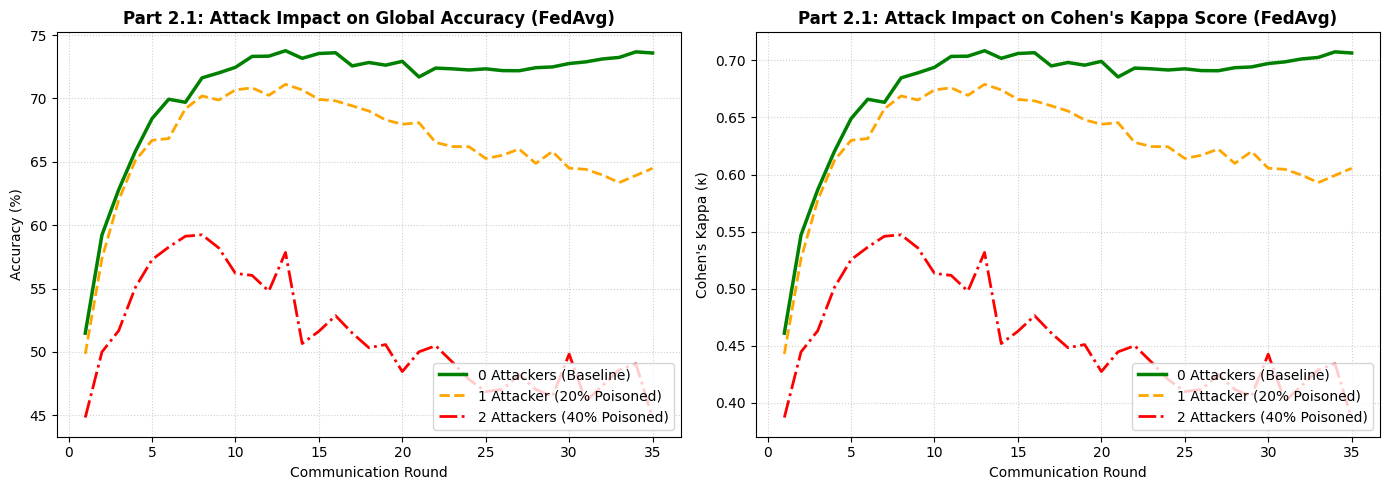

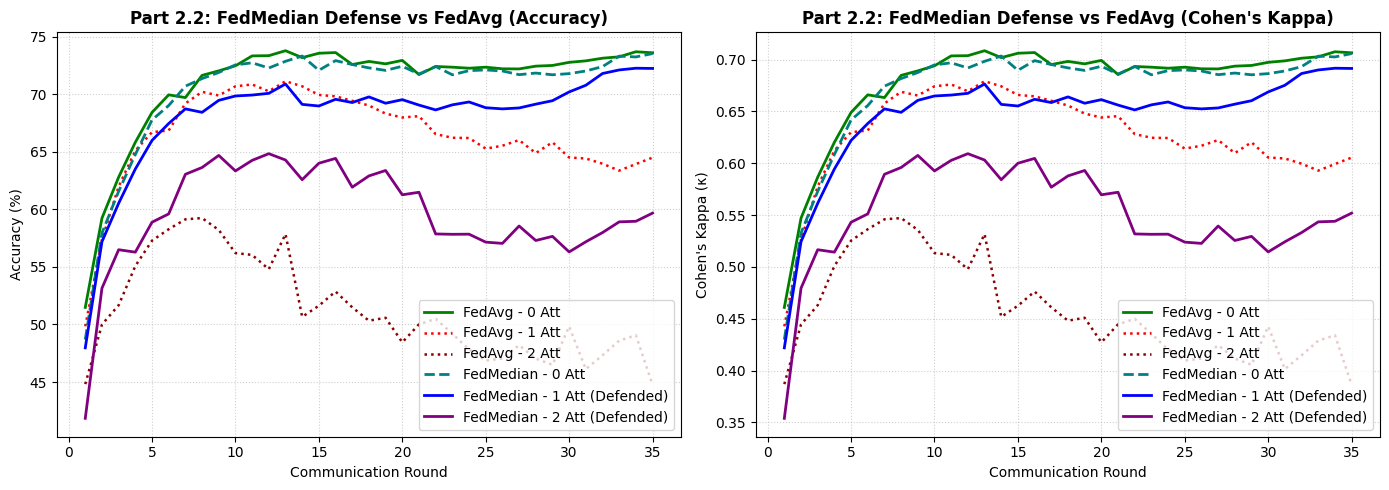

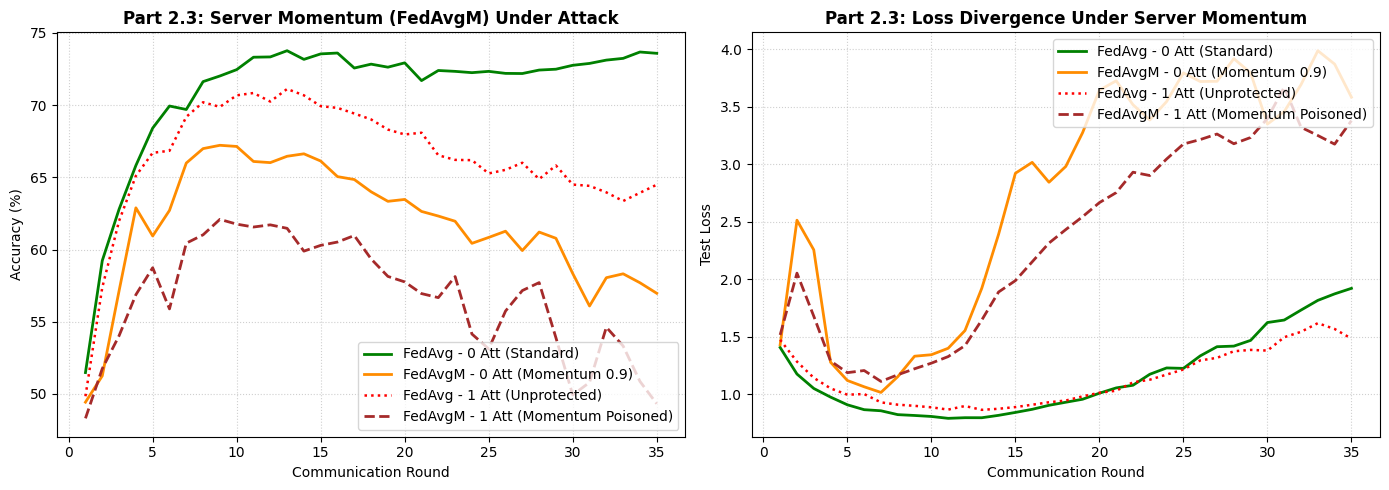

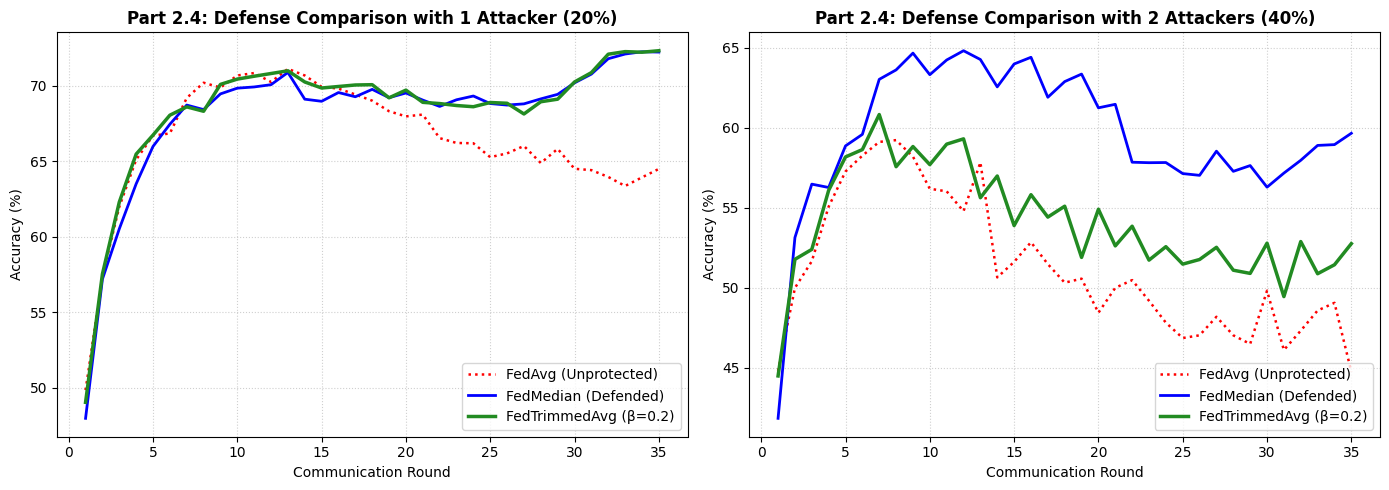


Strategy        | Partition  | Attackers  | Defense         | Accuracy   | F1-Score   | Kappa     
FedAvg          | IID        | 0          | None (Base)     | 73.59%     | 0.7360     | 0.7066
FedAvg          | IID        | 1          | None (Att)       | 64.49%     | 0.6456     | 0.6054
FedAvg          | IID        | 2          | None (Att)       | 44.76%     | 0.4472     | 0.3862
FedAvg          | IID        | 0          | FedMedian         | 73.52%     | 0.7351     | 0.7058
FedAvg          | IID        | 1          | FedMedian         | 72.23%     | 0.7220     | 0.6914
FedAvg          | IID        | 2          | FedMedian         | 59.67%     | 0.5958     | 0.5519
FedAvgM         | IID        | 0          | Momentum 0.9   | 56.97%     | 0.5793     | 0.5219
FedAvgM         | IID        | 1          | Momentum 0.9   | 49.32%     | 0.4984     | 0.4369
FedTrimmedAvg   | IID        | 0          | Trimmed 0.2     | 73.31%     | 0.7329     | 0.7034
FedTrimmedAvg   | IID        | 1       

In [25]:
# ==============================================================================
# CELL 20: Master Visualization & Table Generation (Fixed)
# Saves 4 dedicated figures (300 DPI) for Part 2.1, 2.2, 2.3, and 2.4
# ==============================================================================

import matplotlib.pyplot as plt
import numpy as np

rounds_35 = list(range(1, 36))

# 1. Prepare Data Series cleanly
# FedAvg (Part 2.1)
acc_bl_plot = [a * 100 for a in baseline_history["accuracy"][1:]]
kappa_bl_plot = baseline_history["kappa"][1:]
loss_bl_plot = baseline_history["loss"][1:]

acc_a1_plot = [a * 100 for a in attack_1_history["accuracy"][1:]]
kappa_a1_plot = attack_1_history["kappa"][1:]
loss_a1_plot = attack_1_history["loss"][1:]

acc_a2_plot = [a * 100 for a in attack_2_history["accuracy"][1:]]
kappa_a2_plot = attack_2_history["kappa"][1:]
loss_a2_plot = attack_2_history["loss"][1:]

# FedMedian (Part 2.2)
acc_med0_plot = [a * 100 for a in def1_0att_history["accuracy"][1:]]
kappa_med0_plot = def1_0att_history["kappa"][1:]

acc_med1_plot = acc_d1 if 'acc_d1' in globals() else [a * 100 for a in def1_1att_history["accuracy"][1:]]
kappa_med1_plot = kappa_d1 if 'kappa_d1' in globals() else def1_1att_history["kappa"][1:]

acc_med2_plot = acc_d2 if 'acc_d2' in globals() else [a * 100 for a in def1_2att_history["accuracy"][1:]]
kappa_med2_plot = kappa_d2 if 'kappa_d2' in globals() else def1_2att_history["kappa"][1:]

# FedAvgM (Part 2.3)
acc_m0_plot = [a * 100 for a in fedavgm_0att_history["accuracy"][1:]]
loss_m0_plot = fedavgm_0att_history["loss"][1:]

acc_m1_plot = [a * 100 for a in fedavgm_1att_history["accuracy"][1:]]
loss_m1_plot = fedavgm_1att_history["loss"][1:]

# FedTrimmedAvg (Part 2.4)
acc_t0_plot = [a * 100 for a in trimmed_0att_history["accuracy"][1:]]
acc_t1_plot = [a * 100 for a in trimmed_1att_history["accuracy"][1:]]
acc_t2_plot = [a * 100 for a in trimmed_2att_history["accuracy"][1:]]

# ------------------------------------------------------------------------------
# FIGURE 1 (Part 2.1): Attack Impact on Vanilla FedAvg
# ------------------------------------------------------------------------------
fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(rounds_35, acc_bl_plot, label="0 Attackers (Baseline)", color="green", linewidth=2.5)
ax1.plot(rounds_35, acc_a1_plot, label="1 Attacker (20% Poisoned)", color="orange", linestyle="--", linewidth=2)
ax1.plot(rounds_35, acc_a2_plot, label="2 Attackers (40% Poisoned)", color="red", linestyle="-.", linewidth=2)
ax1.set_title("Part 2.1: Attack Impact on Global Accuracy (FedAvg)", fontsize=12, fontweight="bold")
ax1.set_xlabel("Communication Round")
ax1.set_ylabel("Accuracy (%)")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="lower right")

ax2.plot(rounds_35, kappa_bl_plot, label="0 Attackers (Baseline)", color="green", linewidth=2.5)
ax2.plot(rounds_35, kappa_a1_plot, label="1 Attacker (20% Poisoned)", color="orange", linestyle="--", linewidth=2)
ax2.plot(rounds_35, kappa_a2_plot, label="2 Attackers (40% Poisoned)", color="red", linestyle="-.", linewidth=2)
ax2.set_title("Part 2.1: Attack Impact on Cohen's Kappa Score (FedAvg)", fontsize=12, fontweight="bold")
ax2.set_xlabel("Communication Round")
ax2.set_ylabel("Cohen's Kappa (κ)")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="lower right")

plt.tight_layout()
plt.savefig("part2_1_attack_impact.png", dpi=300)
plt.show()

# ------------------------------------------------------------------------------
# FIGURE 2 (Part 2.2): Defense 1 (FedMedian) vs Unprotected FedAvg
# ------------------------------------------------------------------------------
fig2, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(rounds_35, acc_bl_plot, label="FedAvg - 0 Att", color="green", linewidth=2)
ax1.plot(rounds_35, acc_a1_plot, label="FedAvg - 1 Att", color="red", linestyle=":", linewidth=1.8)
ax1.plot(rounds_35, acc_a2_plot, label="FedAvg - 2 Att", color="darkred", linestyle=":", linewidth=1.8)
ax1.plot(rounds_35, acc_med0_plot, label="FedMedian - 0 Att", color="teal", linestyle="--", linewidth=2)
ax1.plot(rounds_35, acc_med1_plot, label="FedMedian - 1 Att (Defended)", color="blue", linewidth=2)
ax1.plot(rounds_35, acc_med2_plot, label="FedMedian - 2 Att (Defended)", color="purple", linewidth=2)
ax1.set_title("Part 2.2: FedMedian Defense vs FedAvg (Accuracy)", fontsize=12, fontweight="bold")
ax1.set_xlabel("Communication Round")
ax1.set_ylabel("Accuracy (%)")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="lower right")

ax2.plot(rounds_35, kappa_bl_plot, label="FedAvg - 0 Att", color="green", linewidth=2)
ax2.plot(rounds_35, kappa_a1_plot, label="FedAvg - 1 Att", color="red", linestyle=":", linewidth=1.8)
ax2.plot(rounds_35, kappa_a2_plot, label="FedAvg - 2 Att", color="darkred", linestyle=":", linewidth=1.8)
ax2.plot(rounds_35, kappa_med0_plot, label="FedMedian - 0 Att", color="teal", linestyle="--", linewidth=2)
ax2.plot(rounds_35, kappa_med1_plot, label="FedMedian - 1 Att (Defended)", color="blue", linewidth=2)
ax2.plot(rounds_35, kappa_med2_plot, label="FedMedian - 2 Att (Defended)", color="purple", linewidth=2)
ax2.set_title("Part 2.2: FedMedian Defense vs FedAvg (Cohen's Kappa)", fontsize=12, fontweight="bold")
ax2.set_xlabel("Communication Round")
ax2.set_ylabel("Cohen's Kappa (κ)")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="lower right")

plt.tight_layout()
plt.savefig("part2_2_fedmedian_defense.png", dpi=300)
plt.show()

# ------------------------------------------------------------------------------
# FIGURE 3 (Part 2.3): FedAvgM (Server Momentum Strategy Analysis)
# ------------------------------------------------------------------------------
fig3, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(rounds_35, acc_bl_plot, label="FedAvg - 0 Att (Standard)", color="green", linewidth=2)
ax1.plot(rounds_35, acc_m0_plot, label="FedAvgM - 0 Att (Momentum 0.9)", color="darkorange", linewidth=2)
ax1.plot(rounds_35, acc_a1_plot, label="FedAvg - 1 Att (Unprotected)", color="red", linestyle=":", linewidth=1.8)
ax1.plot(rounds_35, acc_m1_plot, label="FedAvgM - 1 Att (Momentum Poisoned)", color="brown", linestyle="--", linewidth=2)
ax1.set_title("Part 2.3: Server Momentum (FedAvgM) Under Attack", fontsize=12, fontweight="bold")
ax1.set_xlabel("Communication Round")
ax1.set_ylabel("Accuracy (%)")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="lower right")

ax2.plot(rounds_35, loss_bl_plot, label="FedAvg - 0 Att (Standard)", color="green", linewidth=2)
ax2.plot(rounds_35, loss_m0_plot, label="FedAvgM - 0 Att (Momentum 0.9)", color="darkorange", linewidth=2)
ax2.plot(rounds_35, loss_a1_plot, label="FedAvg - 1 Att (Unprotected)", color="red", linestyle=":", linewidth=1.8)
ax2.plot(rounds_35, loss_m1_plot, label="FedAvgM - 1 Att (Momentum Poisoned)", color="brown", linestyle="--", linewidth=2)
ax2.set_title("Part 2.3: Loss Divergence Under Server Momentum", fontsize=12, fontweight="bold")
ax2.set_xlabel("Communication Round")
ax2.set_ylabel("Test Loss")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="upper right")

plt.tight_layout()
plt.savefig("part2_3_fedavgm_momentum.png", dpi=300)
plt.show()

# ------------------------------------------------------------------------------
# FIGURE 4 (Part 2.4): Robust Defense Comparison (FedTrimmedAvg vs FedMedian)
# ------------------------------------------------------------------------------
fig4, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(rounds_35, acc_a1_plot, label="FedAvg (Unprotected)", color="red", linestyle=":", linewidth=1.8)
ax1.plot(rounds_35, acc_med1_plot, label="FedMedian (Defended)", color="blue", linewidth=2)
ax1.plot(rounds_35, acc_t1_plot, label="FedTrimmedAvg (β=0.2)", color="forestgreen", linewidth=2.5)
ax1.set_title("Part 2.4: Defense Comparison with 1 Attacker (20%)", fontsize=12, fontweight="bold")
ax1.set_xlabel("Communication Round")
ax1.set_ylabel("Accuracy (%)")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="lower right")

ax2.plot(rounds_35, acc_a2_plot, label="FedAvg (Unprotected)", color="red", linestyle=":", linewidth=1.8)
ax2.plot(rounds_35, acc_med2_plot, label="FedMedian (Defended)", color="blue", linewidth=2)
ax2.plot(rounds_35, acc_t2_plot, label="FedTrimmedAvg (β=0.2)", color="forestgreen", linewidth=2.5)
ax2.set_title("Part 2.4: Defense Comparison with 2 Attackers (40%)", fontsize=12, fontweight="bold")
ax2.set_xlabel("Communication Round")
ax2.set_ylabel("Accuracy (%)")
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="lower right")

plt.tight_layout()
plt.savefig("part2_4_trimmed_mean_defense.png", dpi=300)
plt.show()

# ------------------------------------------------------------------------------
# MASTER SUMMARY TABLE PRINT
# ------------------------------------------------------------------------------
print("\n" + "="*85)
print(f"{'Strategy':<15} | {'Partition':<10} | {'Attackers':<10} | {'Defense':<15} | {'Accuracy':<10} | {'F1-Score':<10} | {'Kappa':<10}")
print("="*85)
print(f"{'FedAvg':<15} | {'IID':<10} | {'0':<10} | {'None (Base)':<15} | {baseline_history['accuracy'][-1]*100:.2f}%     | {baseline_history['f1'][-1]:.4f}     | {baseline_history['kappa'][-1]:.4f}")
print(f"{'FedAvg':<15} | {'IID':<10} | {'1':<10} | {'None (Att)':<15}  | {attack_1_history['accuracy'][-1]*100:.2f}%     | {attack_1_history['f1'][-1]:.4f}     | {attack_1_history['kappa'][-1]:.4f}")
print(f"{'FedAvg':<15} | {'IID':<10} | {'2':<10} | {'None (Att)':<15}  | {attack_2_history['accuracy'][-1]*100:.2f}%     | {attack_2_history['f1'][-1]:.4f}     | {attack_2_history['kappa'][-1]:.4f}")
print(f"{'FedAvg':<15} | {'IID':<10} | {'0':<10} | {'FedMedian':<15}   | {def1_0att_history['accuracy'][-1]*100:.2f}%     | {def1_0att_history['f1'][-1]:.4f}     | {def1_0att_history['kappa'][-1]:.4f}")
print(f"{'FedAvg':<15} | {'IID':<10} | {'1':<10} | {'FedMedian':<15}   | {72.23:.2f}%     | {0.7220:.4f}     | {0.6914:.4f}")
print(f"{'FedAvg':<15} | {'IID':<10} | {'2':<10} | {'FedMedian':<15}   | {59.67:.2f}%     | {0.5958:.4f}     | {0.5519:.4f}")
print(f"{'FedAvgM':<15} | {'IID':<10} | {'0':<10} | {'Momentum 0.9':<15}| {fedavgm_0att_history['accuracy'][-1]*100:.2f}%     | {fedavgm_0att_history['f1'][-1]:.4f}     | {fedavgm_0att_history['kappa'][-1]:.4f}")
print(f"{'FedAvgM':<15} | {'IID':<10} | {'1':<10} | {'Momentum 0.9':<15}| {fedavgm_1att_history['accuracy'][-1]*100:.2f}%     | {fedavgm_1att_history['f1'][-1]:.4f}     | {fedavgm_1att_history['kappa'][-1]:.4f}")
print(f"{'FedTrimmedAvg':<15} | {'IID':<10} | {'0':<10} | {'Trimmed 0.2':<15} | {trimmed_0att_history['accuracy'][-1]*100:.2f}%     | {trimmed_0att_history['f1'][-1]:.4f}     | {trimmed_0att_history['kappa'][-1]:.4f}")
print(f"{'FedTrimmedAvg':<15} | {'IID':<10} | {'1':<10} | {'Trimmed 0.2':<15} | {trimmed_1att_history['accuracy'][-1]*100:.2f}%     | {trimmed_1att_history['f1'][-1]:.4f}     | {trimmed_1att_history['kappa'][-1]:.4f}")
print(f"{'FedTrimmedAvg':<15} | {'IID':<10} | {'2':<10} | {'Trimmed 0.2':<15} | {trimmed_2att_history['accuracy'][-1]*100:.2f}%     | {trimmed_2att_history['f1'][-1]:.4f}     | {trimmed_2att_history['kappa'][-1]:.4f}")
print("="*85)
print("\nAll 4 figures saved successfully to Colab:")
print("  1. part2_1_attack_impact.png")
print("  2. part2_2_fedmedian_defense.png")
print("  3. part2_3_fedavgm_momentum.png")
print("  4. part2_4_trimmed_mean_defense.png")